In [63]:
!pip install requests beautifulsoup4 lxml

import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from bs4 import BeautifulSoup

In [64]:
url = "https://www.worldometers.info/world-population/iran-population/"

headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(url, headers=headers)

print("Status code:", response.status_code)

Status code: 200


In [71]:
soup = BeautifulSoup(response.text, "html.parser")
tables = soup.find_all("table")

print("Number of tables:", len(tables))

Number of tables: 3


In [67]:
tables = pd.read_html(response.text)

print("Tables extracted:", len(tables))

for i, table in enumerate(tables):
    print(f"\nTable {i}")
    print(table.head())

Tables extracted: 3

Table 0
   Year  Population Yearly % Change  Yearly Change Migrants (net)  Median Age  \
0  2026    93168497           0.81%         750816          66848        34.5   
1  2025    92417681           0.93%         849943         116786        34.0   
2  2024    91567738           1.06%         959031         190156        33.4   
3  2023    90608707           1.21%        1084461         262044        32.9   
4  2022    89524246           1.02%         900402         403190        32.3   

   Fertility Rate  Density (P/KmÂ²) Urban Pop %  Urban Population  \
0            1.66                57       73.5%          68514252   
1            1.67                57       73.3%          67760281   
2            1.68                56       73.1%          66968458   
3            1.70                56         73%          66139220   
4            1.70                55       72.9%          65271669   

  Country's Share of World Pop  World Population  Iran Global Rank  


/var/folders/3w/j2_fg0d523936yvf9qb8h97m0000gn/T/ipykernel_14547/3076117983.py:1: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  tables = pd.read_html(response.text)


In [68]:
df = tables[1].copy()

df.head()

,Year,Population,Yearly % Change,Yearly Change,Migrants (net),Median Age,Fertility Rate,Density (P/KmÂ²),Urban Pop %,Urban Population,Country's Share of World Pop,World Population,Iran Global Rank
0,2030,95486667,0.66%,613797,"â38,565",36.7,1.63,59,74.6%,71204909,1.1%,8569124911,17
1,2035,97679252,0.46%,438517,"â37,446",39.0,1.63,60,75.9%,74092307,1.1%,8885210181,17
2,2040,99524277,0.37%,369005,"â35,646",40.8,1.63,61,77%,76665787,1.1%,9177190203,18
3,2045,100990613,0.29%,293267,"â35,872",42.2,1.63,62,78.1%,78860081,1.1%,9439639668,18
4,2050,101861993,0.17%,174276,"â31,191",43.5,1.63,63,79%,80441107,1.1%,9664378587,18


In [45]:
countries = [
    "Iran",
    "Lithuania",
    "Germany",
    "France",
    "Poland"
]

df_selected = df[df["Entity"].isin(countries)].copy()

print("countries:")
print(df_selected["Entity"].unique())

print(f"\n observations: {len(df_selected):,}")


countries:
['France' 'Germany' 'Iran' 'Lithuania' 'Poland']

 observations: 1,305


In [46]:
df_selected = df_selected[
    (df_selected["Year"] >= 1990) &
    (df_selected["Year"] <= 2023)
].copy()

print(
    f"Analysis period: {df_selected['Year'].min()}–{df_selected['Year'].max()}"
)

print(
    f"Number of observations: {len(df_selected):,}"
)

Analysis period: 1990–2023
Number of observations: 170


In [47]:
df_selected = df_selected.sort_values(
    ["Entity", "Year"]
)

df_selected["Population_Growth_%"] = (
    df_selected.groupby("Entity")["Population"]
    .pct_change() * 100
)

display(df_selected.head(15))

,Entity,Code,Year,Population,Population_Growth_%
18625,France,FRA,1990,56990239,NaN
18626,France,FRA,1991,57271564,0.493637
18627,France,FRA,1992,57554867,0.494666
18628,France,FRA,1993,57801261,0.428103
18629,France,FRA,1994,57999868,0.343603
18630,France,FRA,1995,58192207,0.331620
18631,France,FRA,1996,58380638,0.323808
18632,France,FRA,1997,58568662,0.322066
18633,France,FRA,1998,58778817,0.358818
18634,France,FRA,1999,59084209,0.519561


In [48]:
df_analysis = df_selected.dropna(
    subset=["Population_Growth_%"]
).copy()

print(f"Observations after removing missing growth values: {len(df_analysis):,}")

display(df_analysis.head())

Observations after removing missing growth values: 165


,Entity,Code,Year,Population,Population_Growth_%
18626,France,FRA,1991,57271564,0.493637
18627,France,FRA,1992,57554867,0.494666
18628,France,FRA,1993,57801261,0.428103
18629,France,FRA,1994,57999868,0.343603
18630,France,FRA,1995,58192207,0.331620


In [50]:
descriptive_stats = (
    df_analysis
    .groupby("Entity")["Population_Growth_%"]
    .describe()
)

descriptive_stats

,count,mean,std,min,25%,50%,75%,max
Entity,,,,,,,,
France,33.0,0.466055,0.157638,0.243546,0.323808,0.492669,0.557001,0.735243
Germany,33.0,0.179469,0.370528,-0.493776,-0.023033,0.154715,0.412747,0.862008
Iran,33.0,1.342192,0.508271,0.190624,1.114557,1.259544,1.449110,2.752364
Lithuania,33.0,-0.776952,0.716504,-2.229994,-1.129426,-0.833773,-0.638536,1.319915
Poland,33.0,0.056165,0.264225,-0.342412,-0.067697,-0.021681,0.102655,0.982430


In [51]:
overall_stats = df_analysis["Population_Growth_%"].describe()

print("Overall descriptive statistics:")
print(overall_stats)

Overall descriptive statistics:
count    165.000000
mean       0.253386
std        0.816103
min       -2.229994
25%       -0.094125
50%        0.256202
75%        0.708454
max        2.752364
Name: Population_Growth_%, dtype: float64


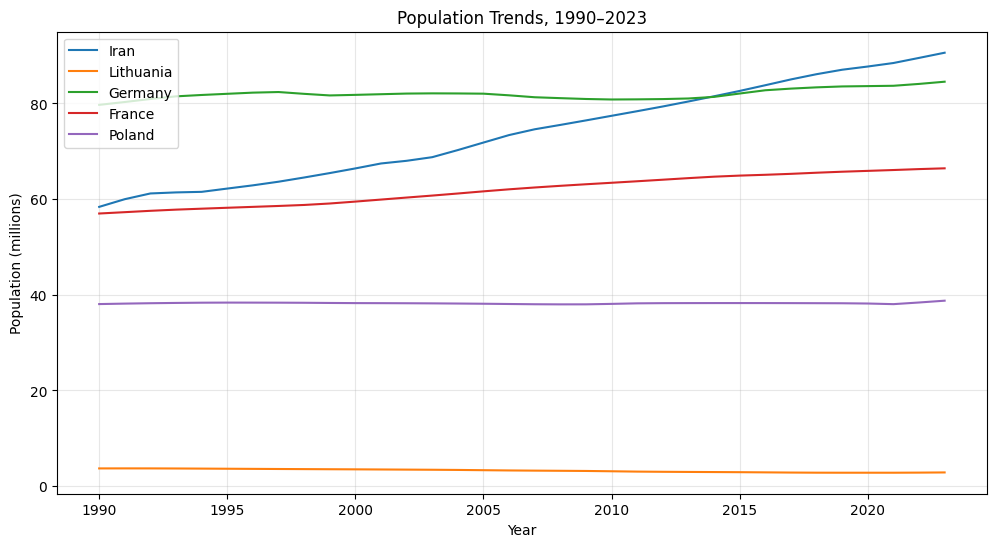

In [52]:
plt.figure(figsize=(12, 6))

for country in countries:
    country_data = df_selected[
        df_selected["Entity"] == country
    ]
    
    plt.plot(
        country_data["Year"],
        country_data["Population"] / 1_000_000,
        label=country
    )

plt.title("Population Trends, 1990–2023")
plt.xlabel("Year")
plt.ylabel("Population (millions)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

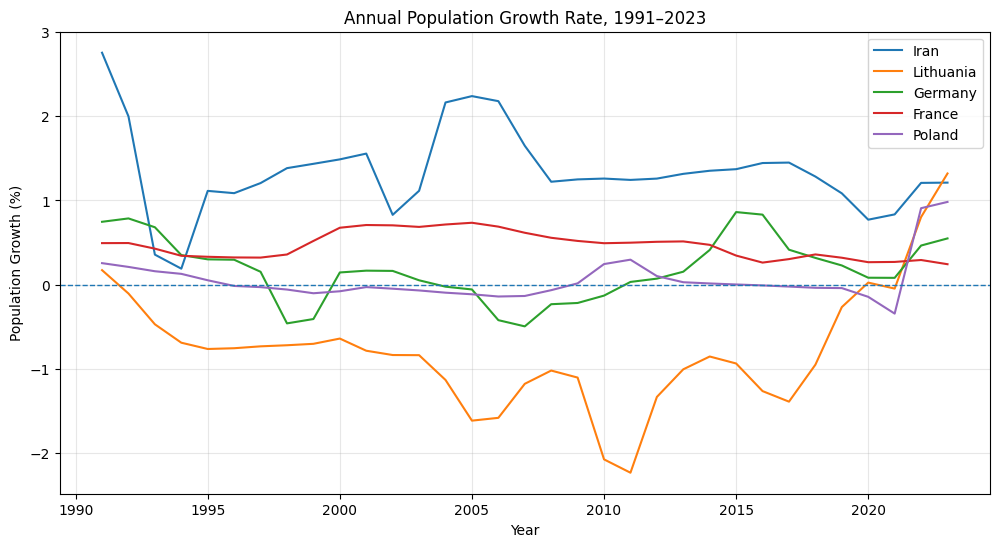

In [53]:
plt.figure(figsize=(12, 6))

for country in countries:
    country_data = df_analysis[
        df_analysis["Entity"] == country
    ]
    
    plt.plot(
        country_data["Year"],
        country_data["Population_Growth_%"],
        label=country
    )

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

plt.title("Annual Population Growth Rate, 1991–2023")
plt.xlabel("Year")
plt.ylabel("Population Growth (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [54]:
iran_growth = df_analysis[
    df_analysis["Entity"] == "Iran"
]["Population_Growth_%"]

lithuania_growth = df_analysis[
    df_analysis["Entity"] == "Lithuania"
]["Population_Growth_%"]

t_stat, p_value = stats.ttest_ind(
    iran_growth,
    lithuania_growth,
    equal_var=False
)

print(f"t-statistic: {t_stat:.4f}")
print(f"p-value: {p_value:.6f}")

t-statistic: 13.8576
p-value: 0.000000


In [61]:
alpha = 0.05

print(f"Significance level: {alpha}")
print(f"p-value: {p_value:.6f}")

if p_value < alpha:
    print(
        "\nResult: Reject the null hypothesis."
    )
    print(
        "There is  evidence for mean population growth rates differ between Iran and Lithuania."
    )
else:
    print(
        "\nResult: Fail to reject the null hypothesis."
    )
    print(
        "There is no evidence for mean population growth rates differ between Iran and Lithuania."
    )

Significance level: 0.05
p-value: 0.000000

Result: Reject the null hypothesis.
There is  evidence for mean population growth rates differ between Iran and Lithuania.


In [57]:
iran_mean = iran_growth.mean()
lithuania_mean = lithuania_growth.mean()

print(f"Iran mean annual population growth: {iran_mean:.3f}%")
print(f"Lithuania mean annual population growth: {lithuania_mean:.3f}%")

Iran mean annual population growth: 1.342%
Lithuania mean annual population growth: -0.777%


In [58]:
def mean_confidence_interval(data, confidence=0.95):
    mean = np.mean(data)
    sem = stats.sem(data)
    margin = sem * stats.t.ppf(
        (1 + confidence) / 2,
        len(data) - 1
    )
    
    return mean - margin, mean + margin


iran_ci = mean_confidence_interval(iran_growth)
lithuania_ci = mean_confidence_interval(lithuania_growth)

print(
    f"Iran 95% confidence interval: "
    f"{iran_ci[0]:.3f}% to {iran_ci[1]:.3f}%"
)

print(
    f"Lithuania 95% confidence interval: "
    f"{lithuania_ci[0]:.3f}% to {lithuania_ci[1]:.3f}%"
)

Iran 95% confidence interval: 1.162% to 1.522%
Lithuania 95% confidence interval: -1.031% to -0.523%


/var/folders/3w/j2_fg0d523936yvf9qb8h97m0000gn/T/ipykernel_14547/1591169551.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


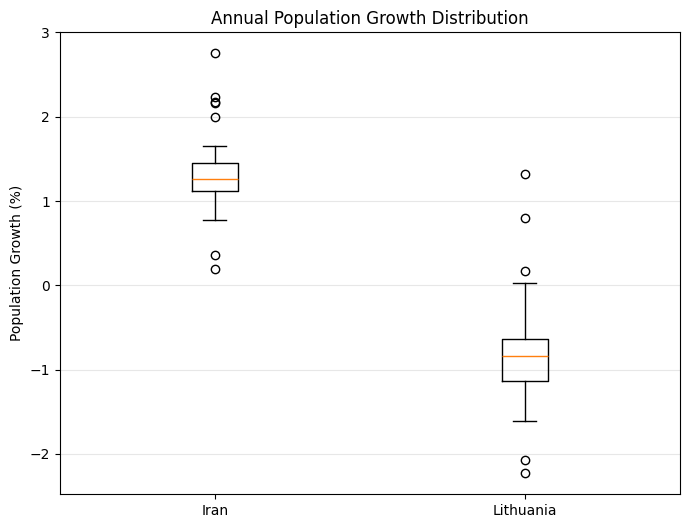

In [59]:
plt.figure(figsize=(8, 6))

plt.boxplot(
    [iran_growth, lithuania_growth],
    labels=["Iran", "Lithuania"]
)

plt.title("Annual Population Growth Distribution")
plt.ylabel("Population Growth (%)")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [60]:
summary = (
    df_analysis
    .groupby("Entity")["Population_Growth_%"]
    .agg(
        Mean="mean",
        Median="median",
        Standard_Deviation="std",
        Minimum="min",
        Maximum="max"
    )
    .round(3)
)

summary

,Mean,Median,Standard_Deviation,Minimum,Maximum
Entity,,,,,
France,0.466,0.493,0.158,0.244,0.735
Germany,0.179,0.155,0.371,-0.494,0.862
Iran,1.342,1.260,0.508,0.191,2.752
Lithuania,-0.777,-0.834,0.717,-2.230,1.320
Poland,0.056,-0.022,0.264,-0.342,0.982
